# 04 Does competition lower the price?

For lots where the buyer published an estimate I compare the winning price with the estimate.
`price_to_estimate` = winning value / estimated value (0.9 means 10% below the estimate).
Only lots with one winner, no framework agreements and a ratio between 0.2 and 3 (see `sql/model.sql`).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

con = duckdb.connect("../data/tenders.duckdb", read_only=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)


def q(sql):
    return con.sql(sql).df()

In [2]:
prices = q('''
SELECT f.*, d.division_name_en
FROM fact_lot f
JOIN dim_cpv d USING (cpv_division)
WHERE price_to_estimate IS NOT NULL AND n_offers >= 1
''')
len(prices)

27551

In [3]:
prices["offers"] = prices["n_offers"].clip(upper=10)
by_offers = prices.groupby("offers")["price_to_estimate"].agg(["count", "median", "mean"])
by_offers

,count,median,mean
offers,,,
1.00,12986,1.00,1.02
2.00,4966,0.94,0.94
3.00,3441,0.90,0.90
4.00,2248,0.85,0.85
5.00,1443,0.85,0.84
6.00,888,0.79,0.81
7.00,507,0.78,0.79
8.00,331,0.78,0.80
9.00,213,0.76,0.76


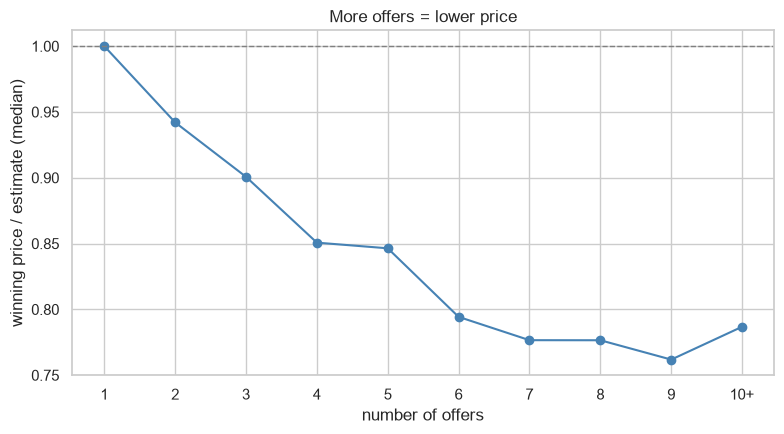

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_offers.index, by_offers["median"], marker="o", color="steelblue")
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xticks(range(1, 11), [str(i) for i in range(1, 10)] + ["10+"])
ax.set(xlabel="number of offers", ylabel="winning price / estimate (median)",
       title="More offers = lower price")
plt.tight_layout()
plt.savefig("../images/price_vs_offers.png", dpi=120)

With one offer the median winner asks exactly the estimate. Each next offer lowers the price,
with 4-5 offers it is about 15% below the estimate.

One reason for the "exactly 1.0": in Poland the buyer has to publish the amount it plans to spend
right before opening the offers, so a company that is alone has no reason to go below it.

## Is it just the category?

Maybe categories with more offers are simply cheaper. To check this I fit a regression
with category, contract type and year as controls.

In [5]:
import numpy as np
import statsmodels.formula.api as smf

prices["log_ratio"] = np.log(prices["price_to_estimate"])
prices["log_offers"] = np.log(prices["n_offers"])

model = smf.ols(
    "log_ratio ~ log_offers + C(cpv_division) + C(contract_nature) + C(year)", data=prices
).fit(cov_type="HC1")
print(f"log_offers coef: {model.params['log_offers']:.4f}, p-value: {model.pvalues['log_offers']:.2g}")
print(f"R2: {model.rsquared:.3f}, n = {int(model.nobs)}")

log_offers coef: -0.1317, p-value: 0
R2: 0.110, n = 27551


In [6]:
b = model.params["log_offers"]
for k in [2, 3, 5]:
    print(f"{k} offers vs 1 offer: {(k ** b - 1):.1%} price difference")

2 offers vs 1 offer: -8.7% price difference
3 offers vs 1 offer: -13.5% price difference
5 offers vs 1 offer: -19.1% price difference


The effect stays after controlling for category, contract type and year: doubling the number of
offers lowers the price by about 9%.

## Single offer by category

In [7]:
single = (
    prices.assign(two_plus=prices["n_offers"] >= 2)
    .groupby(["division_name_en", "two_plus"])["price_to_estimate"]
    .median()
    .unstack()
    .rename(columns={False: "one_offer", True: "two_or_more"})
    .dropna()
)
single["gap"] = single["one_offer"] - single["two_or_more"]
counts = prices.groupby("division_name_en").size()
single = single[counts.reindex(single.index) >= 300].sort_values("gap", ascending=False)
single.index = single.index.str.slice(0, 50)
single.head(10)

two_plus,one_offer,two_or_more,gap
division_name_en,,,
Education and training services,1.10,0.80,0.30
Construction work,1.06,0.76,0.29
"Agricultural, forestry, horticultural, aquacultura",0.89,0.67,0.23
"Architectural, construction, engineering and inspe",1.07,0.86,0.20
Construction structures and materials; auxiliary p,1.00,0.83,0.17
"Sewage, refuse, cleaning and environmental service",1.00,0.87,0.13
Transport equipment and auxiliary products to tran,1.08,0.96,0.12
"Furniture (incl. office furniture), furnishings, d",1.00,0.90,0.10
"Medical equipments, pharmaceuticals and personal c",1.00,0.90,0.10


## How much could buyers save?

A rough estimate: if single-offer lots got the same price ratio as lots with 2 offers.
This is not exact (we don't know if more companies would apply), but it shows the scale.

In [8]:
ratio_1 = by_offers.loc[1, "median"]
ratio_2 = by_offers.loc[2, "median"]
single_value = q('''
SELECT year, sum(value_pln) AS value
FROM fact_lot
WHERE single_offer AND NOT framework
GROUP BY 1
ORDER BY 1
''')
single_value["possible_saving_bln"] = single_value["value"] * (1 - ratio_2 / ratio_1) / 1e9
single_value["value_bln"] = single_value["value"] / 1e9
single_value[["year", "value_bln", "possible_saving_bln"]]

,year,value_bln,possible_saving_bln
0,2024,48.77,2.83
1,2025,80.28,4.65
2,2026,108.20,6.27


## Summary

- with 1 offer the price is on average equal to the estimate, with 2 offers ~6% lower,
  with 4-5 offers ~15% lower
- the effect holds after controlling for category, contract type and year
- getting a second offer in single-offer lots could save a few billion PLN per year
- for a company: in categories with one offer the price is close to the published budget,
  so the margin is higher